# 01 — Exploratory Data Analysis (EDA)

**Purpose:** Understand what the data looks like, which client groups have higher default rates, and whether the derived features carry any signal, to prepare for modelling.

**Reference document:** `docs/project-notes.md` (repository-local summary of the project plan). The derived-feature definitions are implemented in `src/features.py`, which is the single source of truth shared by this notebook, notebook 02 and the smoke test. The SQL layer remains the formal cleaning layer; pandas is used here to build the same features so the notebook can run on its own.

**Data:** UCI "Default of Credit Card Clients" — Taiwan credit card clients, April–September 2005, 30,000 rows. **Note:** This is old data from 2005. It is suitable only as a portfolio demonstration and does not represent the current Hong Kong market.

**Raw file (defect 1):** the tracked raw file is tab-separated text, *not* an Excel workbook, even though it was uploaded with a `.xls` name. Its canonical name is `raw data/Default of Credit Card Clients.tsv` and it is loaded with `pandas.read_csv(..., sep="\t", header=1)`. Do not describe it as a valid `.xls` file and do not try to read it with an Excel reader.


## 0. Before reading the data

- The tracked raw file is TSV text: first row X1, X2, ...; real column names in the second row, so read it with `sep="\t", header=1`.
- After reading, rename `default payment next month` to `default_payment_next_month` (1 = default next month, 0 = no default).
- `PAY_0` is the most recent month (September 2005) and `PAY_6` is the earliest month (April). Note that there is no `PAY_1`.
- Schema assertions run on load: 30,000 rows, 25 raw columns, unique ID, zero raw nulls, 6,636 defaults (see `src/data_loading.py`).


In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find the project root: works whether run from notebooks/ or from the project root
_CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (p for p in _CANDIDATES if (p / "raw data" / "Default of Credit Card Clients.tsv").exists()),
    Path.cwd().parent,
)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
from data_loading import load_raw_tsv, assert_raw_schema, RAW_TSV_NAME
from features import build_features, assert_features_schema

RAW_PATH = PROJECT_ROOT / "raw data" / RAW_TSV_NAME
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)
print("Raw file:", RAW_PATH, "exists:", RAW_PATH.exists())


Project root: /home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/clean-verification
Raw file: /home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/clean-verification/raw data/Default of Credit Card Clients.tsv exists: True


In [2]:
# Read the tracked TSV: sep="\t", header=1 (the second row holds the real column names)
df = load_raw_tsv(RAW_PATH)
assert_raw_schema(df)

print("Shape (rows, columns):", df.shape)
print("ID is unique:", df["ID"].is_unique)
print("Total missing values:", int(df.isna().sum().sum()))
print("Columns:", list(df.columns))
df.head(3)


Shape (rows, columns): (30000, 25)
ID is unique: True
Total missing values: 0
Columns: ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default_payment_next_month']


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


## 1. Target variable: default is the minority class

Default clients are about one in five. All evaluation must start from this fact: **accuracy can be reported, but it must always be reported together with AUC, recall, and precision** — if a model predicted "no default" for everyone, accuracy would still look high, but it would catch no defaulters at all.


Default (1): 6636 clients
No default (0): 23364 clients
Overall default rate: 22.12 %


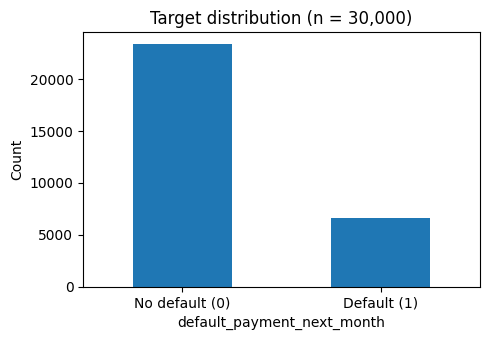

In [3]:
target = df["default_payment_next_month"]
print("Default (1):", int((target == 1).sum()), "clients")
print("No default (0):", int((target == 0).sum()), "clients")
print("Overall default rate:", round(target.mean() * 100, 2), "%")

ax = target.value_counts().sort_index().plot(kind="bar", figsize=(5, 3.5))
ax.set_xticklabels(["No default (0)", "Default (1)"], rotation=0)
ax.set_title("Target distribution (n = 30,000)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

## 2. Categorical fields: look first, do not rush to change them

Focus on where unknown codes are hidden: besides 1 = graduate school, 2 = university, 3 = high school, and 4 = others, `EDUCATION` also has 0, 5, and 6; besides 1 = married, 2 = single, and 3 = others, `MARRIAGE` also has 0. These unknown categories should be merged, not deleted (see `sql/README.md`, cleaning decisions).


In [4]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).sort_index().to_string())
    print()

print("--- PAY_0 (most recent month repayment status) ---")
print(df["PAY_0"].value_counts(dropna=False).sort_index().to_string())
print()
print("PAY scale: -2 = no consumption; -1 = paid duly; 0 = revolving credit; 1-9 = months delayed")

--- SEX ---
SEX
1    11888
2    18112

--- EDUCATION ---
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51

--- MARRIAGE ---
MARRIAGE
0       54
1    13659
2    15964
3      323

--- PAY_0 (most recent month repayment status) ---
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19

PAY scale: -2 = no consumption; -1 = paid duly; 0 = revolving credit; 1-9 = months delayed


## 3. Default rate by repayment status (PAY_0, most recent month)

**How to read it:** the more months delayed, the higher the default rate should be. If a group does not follow this direction, stop and check whether the coding was misunderstood (for example, -2, -1, and 0 are not delays).


 PAY_0     n  default_rate  default_rate_pct
    -2  2759      0.132294              13.2
    -1  5686      0.167781              16.8
     0 14737      0.128113              12.8
     1  3688      0.339479              33.9
     2  2667      0.691414              69.1
     3   322      0.757764              75.8
     4    76      0.684211              68.4
     5    26      0.500000              50.0
     6    11      0.545455              54.5
     7     9      0.777778              77.8
     8    19      0.578947              57.9


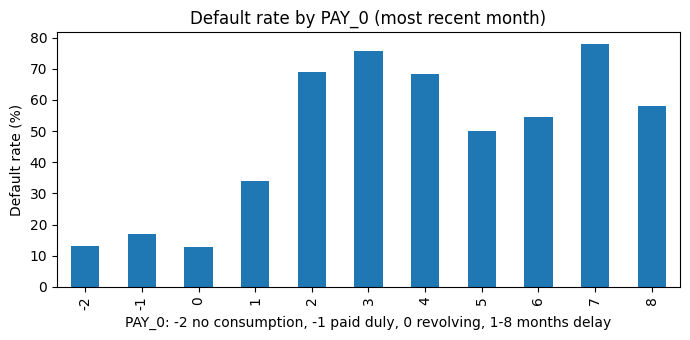

In [5]:
pay0_rate = (
    df.groupby("PAY_0")["default_payment_next_month"]
    .agg(n="size", default_rate="mean")
    .reset_index()
)
pay0_rate["default_rate_pct"] = (pay0_rate["default_rate"] * 100).round(1)
print(pay0_rate.to_string(index=False))

ax = pay0_rate.plot(kind="bar", x="PAY_0", y="default_rate_pct",
                    figsize=(7, 3.5), legend=False)
ax.set_title("Default rate by PAY_0 (most recent month)")
ax.set_xlabel("PAY_0: -2 no consumption, -1 paid duly, 0 revolving, 1-8 months delay")
ax.set_ylabel("Default rate (%)")
plt.tight_layout()
plt.show()

## 4. Default rate by credit limit (LIMIT_BAL quartiles)


       limit_quartile    n  default_rate  default_rate_pct
  (9999.999, 50000.0] 7676      0.317874              31.8
  (50000.0, 140000.0] 7614      0.247176              24.7
 (140000.0, 240000.0] 7643      0.173492              17.3
(240000.0, 1000000.0] 7067      0.139805              14.0


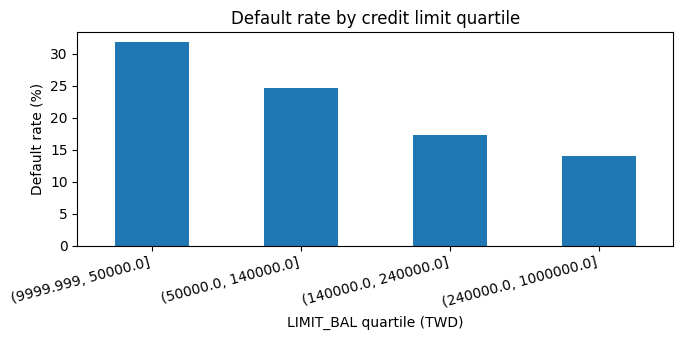

In [6]:
df["limit_quartile"] = pd.qcut(df["LIMIT_BAL"], 4, duplicates="drop")
limit_rate = (
    df.groupby("limit_quartile", observed=True)["default_payment_next_month"]
    .agg(n="size", default_rate="mean")
    .reset_index()
)
limit_rate["default_rate_pct"] = (limit_rate["default_rate"] * 100).round(1)
print(limit_rate.to_string(index=False))

ax = limit_rate.plot(kind="bar", x="limit_quartile", y="default_rate_pct",
                     figsize=(7, 3.5), legend=False)
ax.set_title("Default rate by credit limit quartile")
ax.set_xlabel("LIMIT_BAL quartile (TWD)")
ax.set_ylabel("Default rate (%)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 5. Default rate by education and marital status


In [7]:
for col in ["EDUCATION", "MARRIAGE"]:
    t = (
        df.groupby(col)["default_payment_next_month"]
        .agg(n="size", default_rate="mean")
        .reset_index()
    )
    t["default_rate_pct"] = (t["default_rate"] * 100).round(1)
    print(f"--- {col} ---")
    print(t.to_string(index=False))
    print()

--- EDUCATION ---
 EDUCATION     n  default_rate  default_rate_pct
         0    14      0.000000               0.0
         1 10585      0.192348              19.2
         2 14030      0.237349              23.7
         3  4917      0.251576              25.2
         4   123      0.056911               5.7
         5   280      0.064286               6.4
         6    51      0.156863              15.7

--- MARRIAGE ---
 MARRIAGE     n  default_rate  default_rate_pct
        0    54      0.092593               9.3
        1 13659      0.234717              23.5
        2 15964      0.209283              20.9
        3   323      0.260062              26.0



## 6. Numeric field distributions: default vs no default

Look at the descriptive statistics and age distribution for the two groups. `LIMIT_BAL` is strongly right-skewed (a few clients have very high limits), so it needs standardisation before modelling. The age distributions of the two groups do not differ much, so do not expect age to be a strong signal.


--- LIMIT_BAL / AGE by target ---
                           LIMIT_BAL                                                                           AGE                                         
                               count      mean       std      min      25%       50%       75%        max    count  mean  std   min   25%   50%   75%   max
default_payment_next_month                                                                                                                                 
0                            23364.0  178099.7  131628.4  10000.0  70000.0  150000.0  250000.0  1000000.0  23364.0  35.4  9.1  21.0  28.0  34.0  41.0  79.0
1                             6636.0  130109.7  115378.5  10000.0  50000.0   90000.0  200000.0   740000.0   6636.0  35.7  9.7  21.0  28.0  34.0  42.0  75.0


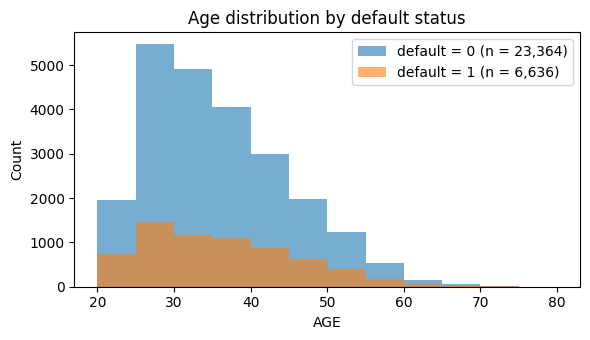

In [8]:
print("--- LIMIT_BAL / AGE by target ---")
print(df.groupby("default_payment_next_month")[["LIMIT_BAL", "AGE"]].describe().round(1).to_string())

fig, ax = plt.subplots(figsize=(6, 3.5))
for label, grp in df.groupby("default_payment_next_month"):
    ax.hist(grp["AGE"], bins=range(20, 81, 5), alpha=0.6,
            label=f"default = {label} (n = {len(grp):,})")
ax.set_title("Age distribution by default status")
ax.set_xlabel("AGE")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Derived features: turning raw fields into risk signals

The definitions are implemented in `src/features.py` (single source of truth), and each feature has a business meaning:

| Derived feature | Definition | Business meaning |
| --- | --- | --- |
| `utilisation_1` | BILL_AMT1 / LIMIT_BAL | Share of the credit limit used in the most recent month |
| `pay_ratio_1` | PAY_AMT1 / BILL_AMT1 | Share of the most recent bill repaid |
| `pay_ratio_avg` | Sum of PAY_AMT over 6 months / sum of BILL_AMT over 6 months | Overall repayment behaviour over six months |
| `pay_ratio_1_denominator_le_0` | 1 when BILL_AMT1 <= 0, else 0 | Flag: the pay_ratio_1 denominator was non-positive, so the ratio is missing |
| `pay_ratio_avg_denominator_le_0` | 1 when sum(BILL_AMT) <= 0, else 0 | Flag: the pay_ratio_avg denominator was non-positive, so the ratio is missing |
| `max_delay_6m` | Maximum of the six delay-month values | Worst delay in six months |
| `delay_months_cnt` | Number of months with delay >= 1 month in six months | Whether delay is occasional or habitual |
| `consecutive_delay` | Consecutive months with delay >= 1 month starting from the most recent month, stopping at the first break | Whether there is a recent run of delays |
| `bill_trend` | BILL_AMT1 − BILL_AMT6 | Trend in bill amounts over six months |

`PAY` raw codes are first converted to delay months (-2/-1/0 -> 0, 1-9 unchanged). The original columns are not overwritten. Zero-division handling: when a denominator is 0 or negative, set the ratio to missing **and** set the corresponding flag to 1, rather than forcing a ratio. The flags are carried into `credit_features.csv` and into the model feature list in notebook 02. Expected pre-imputation missing counts: `pay_ratio_1` 2,598, `pay_ratio_avg` 1,071, `utilisation_1` 0.


In [9]:
# Build features with the shared implementation (src/features.py).
# This keeps notebook 01, notebook 02 and the smoke test on identical features.
features = build_features(df)
assert_features_schema(features)

out_path = PROCESSED_DIR / "credit_features.csv"
features.to_csv(out_path, index=False)
print("credit_features shape:", features.shape)
print("Saved to:", out_path)
print()
print("Missing values in new features (denominator <= 0 cases):")
print(features[["utilisation_1", "pay_ratio_1", "pay_ratio_avg"]].isna().sum().to_string())
print()
print("Denominator flags (must equal the missing counts above):")
print(features[["pay_ratio_1_denominator_le_0", "pay_ratio_avg_denominator_le_0"]].sum().to_string())
print()
print(features[["utilisation_1", "pay_ratio_1", "pay_ratio_avg", "max_delay_6m",
                "delay_months_cnt", "consecutive_delay", "bill_trend"]].describe().round(2).to_string())


credit_features shape: (30000, 36)
Saved to: /home/hatch/workspace/goals/credit-default-prediction-portfolio-project/hidden_files/defect-fixes/clean-verification/data/processed/credit_features.csv

Missing values in new features (denominator <= 0 cases):
utilisation_1       0
pay_ratio_1      2598
pay_ratio_avg    1071

Denominator flags (must equal the missing counts above):
pay_ratio_1_denominator_le_0      2598
pay_ratio_avg_denominator_le_0    1071

       utilisation_1  pay_ratio_1  pay_ratio_avg  max_delay_6m  delay_months_cnt  consecutive_delay  bill_trend
count       30000.00     27402.00       28929.00      30000.00          30000.00           30000.00    30000.00
mean            0.42         1.78           0.49          0.68              0.83               0.62    12351.57
std             0.41        76.57           5.61          1.07              1.55               1.47    43922.42
min            -0.62         0.00           0.00          0.00              0.00              

## 8. Quick check on derived features: is there a signal?

Look at the two most direct signals: the worst delay in six months (`max_delay_6m`) and the most recent month's limit utilisation (`utilisation_1`, in quartiles). If the default rate rises clearly with delay months, the feature direction is correct — and the next notebook is worth doing.


--- max_delay_6m ---
 max_delay_6m     n  default_rate  default_rate_pct
            0 19931      0.117104              11.7
            1  1689      0.249852              25.0
            2  7187      0.435509              43.6
            3   789      0.622307              62.2
            4   218      0.642202              64.2
            5    69      0.507246              50.7
            6    25      0.560000              56.0
            7    67      0.835821              83.6
            8    25      0.560000              56.0

--- utilisation_1 ---
  utilisation_1    n  default_rate  default_rate_pct
(-0.621, 0.022] 7500      0.210267              21.0
 (0.022, 0.314] 7500      0.157867              15.8
  (0.314, 0.83] 7500      0.251200              25.1
  (0.83, 6.455] 7500      0.265467              26.5



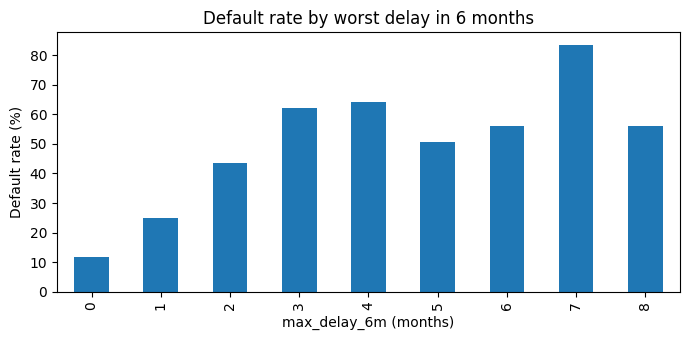

In [10]:
for col, bins in [("max_delay_6m", None), ("utilisation_1", 4)]:
    if bins is None:
        grp = features.groupby(col)["default_payment_next_month"]
    else:
        grp = features.groupby(pd.qcut(features[col], bins, duplicates="drop"),
                               observed=True)["default_payment_next_month"]
    t = grp.agg(n="size", default_rate="mean").reset_index()
    t["default_rate_pct"] = (t["default_rate"] * 100).round(1)
    print(f"--- {col} ---")
    print(t.to_string(index=False))
    print()

ax = features.groupby("max_delay_6m")["default_payment_next_month"].mean().mul(100).plot(
    kind="bar", figsize=(7, 3.5), legend=False)
ax.set_title("Default rate by worst delay in 6 months")
ax.set_xlabel("max_delay_6m (months)")
ax.set_ylabel("Default rate (%)")
plt.tight_layout()
plt.show()

## Next steps

1. Write the 3–5 key findings from the observations above into a first draft of `reports/findings.md` (each finding should point to a specific chart or figure).
2. Go to `02_baseline_logistic.ipynb`: use the same `credit_features.csv`, with a stratified 80/20 split, and build a logistic regression baseline.
